# 011 RNN 图像字幕：题目要求

**需要完成：** 实现单步/序列 RNN、词嵌入、时序仿射和带掩码 Softmax；数值检查完整模型；50 字幕小样本训练 50 轮；实现正确自回归解码并展示图文。

**实验范围与验收：** 新增完整数据训练覆盖每轮全部 400135 条课程字幕，共 20 轮；经对照验证的 GPU 等价后端执行，原 NumPy 教学实验独立保留。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：普通循环网络生成字幕

图像先投影为初始状态。训练读真实前一词，预测真实下一词；生成时读模型自己刚选出的词，训练和生成的输入来源不同。

![普通循环网络生成字幕的数据流](../assets/model_flow/011_RNN_Captioning.svg)

**从定义推到实现。**

$$
h_t=\tanh(e_tW_x+h_{t-1}W_h+b),\quad s_t=h_tW_v+b_v
$$

每步损失对 h_t 的梯度与未来步骤传回的梯度相加，再乘 1−h_t²。各步重复使用同一个 W_h，因此各步的梯度要相加。NULL 填充位置不贡献损失；课程损失按字幕数 N 平均。

**库在这里解决什么问题？** NumPy 查表取得词向量，时间循环保存缓存；h5py 按图像索引读取课程特征。GPU 版本用 PyTorch 重写同一递推，并逐项对照手写梯度。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `__future__` | 声明历史 Python 兼容语义。 |
| `cs231n.beam_search` | 运行字幕模型或解码对照，共享相同的词表、图像索引与评估口径。 |
| `cs231n.captioning_solver` | 负责批次抽样、训练循环和参数更新，使模型的 loss 方法只处理一次计算。 |
| `cs231n.classifiers.rnn` | 加载当前作业的本地实现。模型代码负责计算预测或损失，notebook 用真实输入检查和训练。 |
| `cs231n.coco_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.gradient_check` | 用中心差分近似导数，独立核对手写反向传播。 |
| `cs231n.image_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.rnn_layers` | 调用本题的前向与反向算子，前向返回的缓存会被相应反向函数读取。 |
| `cs231n.torch_captioning` | 运行字幕模型或解码对照，共享相同的词表、图像索引与评估口径。 |
| `json` | 把配置、指标和样例序列化为可读记录，供后续对照。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |
| `time` | 测量代码开始与结束的实际时间，在相同输入上比较实现成本。 |

**用一个小例子检查理解。** 字幕 [START, cat, END, NULL] 形成输入 [START, cat, END] 与目标 [cat, END, NULL]。第三个目标被掩码屏蔽。因此前两步产生学习信号，填充位置不应影响权重。

## 读论文图：一张图片怎样成为一句话？

![Show and Tell 图 1](https://ar5iv.labs.arxiv.org/html/1411.4555/assets/overview_fig_2.png)

Vinyals 等，*Show and Tell*，CVPR 2015，图 1，PDF 第 1 页。[查看论文原页](https://openaccess.thecvf.com/content_cvpr_2015/papers/Vinyals_Show_and_Tell_2015_CVPR_paper.pdf#page=1)

视觉网络给出图片表示，语言网络在图片和此前词的条件下预测下一词。整句概率是各时间步条件概率的乘积，取负对数后成为逐步交叉熵之和。这就是为什么字幕提供一整行 token，而训练损失需要沿时间求和。

本题读取预先计算的 512 维特征，通过 W_proj 和 b_proj 初始化 h₀。训练时输入真实前一词，生成时必须输入刚预测的词。论文中的 NIC 使用 LSTM，这一册则用普通 tanh RNN；本题没有联合更新图像编码器。

# 图像标题与RNNs
在这个练习中，您将实现一个普通的递归神经网络，并使用它们来训练一个可以为图像生成新标题的模型。

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜导入字幕模型与算子**

导入手写 RNN、词嵌入、时序仿射、时序 Softmax、字幕 Solver 与 COCO 工具。图像已由课程预处理为视觉特征，本题训练字幕解码器，不重新训练图像特征提取网络。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`__future__.print_function`、`time`、`os`、`json`、`numpy`、`matplotlib.pyplot`、`cs231n.gradient_check.eval_numerical_gradient`、`cs231n.gradient_check.eval_numerical_gradient_array`、`cs231n.rnn_layers.*`、`cs231n.captioning_solver.CaptioningSolver`、`cs231n.classifiers.rnn.CaptioningRNN`、`cs231n.coco_utils.load_coco_data`、`cs231n.coco_utils.sample_coco_minibatch`、`cs231n.coco_utils.decode_captions`、`cs231n.image_utils.image_from_url`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 5 块。

In [2]:
# 跟往常一样,有点陷害
from __future__ import print_function
import time, os, json
import numpy as np
import matplotlib.pyplot as plt

from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.rnn_layers import *
from cs231n.captioning_solver import CaptioningSolver
from cs231n.classifiers.rnn import CaptioningRNN
from cs231n.coco_utils import load_coco_data, sample_coco_minibatch, decode_captions
from cs231n.image_utils import image_from_url

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # 设置地块的默认大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# 用于自动重新装入外部模块
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

## 读取 HDF5 数据

课程把字幕、图像索引和视觉特征存放在 HDF5 文件中。h5py 按键读取数组，图像索引把一条字幕连接到对应图像。当前环境已包含 h5py，从本题工作目录启动同名内核即可。

# 微软COCO
对于这个练习，我们将使用2014年发布的[Microsoft COCO数据集](http://mscoco.org/)，它已经成为图像字幕的标准测试平台。该数据集包括80,000张训练图像和40,000张验证图像，每个图像都有5个由Amazon Mechanical Turk上的工作人员编写的注释。
通过切换到“cs231n/datasets”目录并运行脚本“get_assignment3_data.sh”，您应该已经下载了数据。如果您还没有这样做，现在就运行这个脚本。警告:可可数据下载是~1GB。
我们已经对数据进行了预处理并为您提取了特征。对于所有的图像，我们提取了在ImageNet上预先训练的VGG-16网络的fc7层的特征;这些特性存储在文件的train2014_vgg16_fc7.h5’和‘val2014_vgg16_fc7.h5。为了减少处理时间和内存需求，我们将特征的维数从4096降至512;这些特性可以在train2014_vgg16_fc7_pca.h5’和‘val2014_vgg16_fc7_pca.h5”中找到。
原始图像占用了大量空间(近20GB)，所以我们没有在下载中包含它们。但是，所有图像都是从Flickr获取的，训练和验证图像的url存储在文件的train2014_urls.txt”和“val2014_urls.txt。这允许您动态下载图像以实现可视化。由于图像是动态下载的，**您必须连接到互联网才能查看图像**。
处理字符串的效率很低，所以我们将使用字幕的编码版本。每个单词都分配了一个整数ID，允许我们用一个整数序列来表示标题。整数id和单词之间的映射在文件“coco2014_vocab”中。可以使用文件cs231n/coco_utils中的函数decode_captions。将整数id的numpy数组转换回字符串。
我们向词汇表中添加了一些特殊的标记。我们在每个标题的开头和结尾分别添加一个特殊的' <START> '令牌和' <END> '令牌。罕见的单词被替换为特殊的“<UNK>”令牌(表示“未知”)。此外，由于我们希望使用包含不同长度标题的小批量进行训练，所以我们在' <END> '标记之后用特殊的' <NULL> '标记填充短标题，并且不计算' <NULL> '标记的丢失或梯度。由于它们有点麻烦，我们已经为您处理了关于特殊令牌的所有实现细节。
可以使用“cs231n/coco_utils.py”文件中的“load_coco_data”函数加载所有MS-COCO数据(标题、特性、url和词汇表)。运行以下单元格:

**第 3 块｜核对字幕和视觉特征索引**

只读加载课程 COCO 字幕、词表、图像索引及 512 维 PCA 特征。字幕行通过 train_image_idxs 或 val_image_idxs 指向图像特征，多个字幕可以对应同一幅图；打印形状验证这种多对一关系。

本块产出的变量接着用于：`data` → 第 15 块。

In [3]:
# 从磁盘装入COCO 数据;这返回字典
# 我们将用维度降低的功能 来完成这个笔记本,但感觉
# 自由通过改变下面的旗帜来试验原始的特性.
data = load_coco_data(pca_features=True)

# 打印数据词典中的所有密钥和值
for k, v in data.items():
    if type(v) == np.ndarray:
        print(k, type(v), v.shape, v.dtype)
    else:
        print(k, type(v), len(v))

train_captions <class 'numpy.ndarray'> (400135, 17) int32
train_image_idxs <class 'numpy.ndarray'> (400135,) int32
val_captions <class 'numpy.ndarray'> (195954, 17) int32
val_image_idxs <class 'numpy.ndarray'> (195954,) int32
train_features <class 'numpy.ndarray'> (82783, 512) float32
val_features <class 'numpy.ndarray'> (40504, 512) float32
idx_to_word <class 'list'> 1004
word_to_idx <class 'dict'> 1004
train_urls <class 'numpy.ndarray'> (82783,) <U63
val_urls <class 'numpy.ndarray'> (40504,) <U63


## 看看数据
在使用数据集之前，从数据集查看示例总是一个好主意。
您可以使用文件“cs231n/coco_utils”中的“sample_coco_minibatch”函数。从load_coco_data返回的数据结构中提取少量数据。运行以下命令对一小批训练数据进行采样，并显示图像及其说明。多次运行它并查看结果可以帮助您了解数据集。
请注意，我们使用' decode_captions '函数来解码字幕，我们使用Flickr URL动态下载图像，因此**您必须连接到互联网才能查看图像**。

**第 4 块｜阅读图文抽样示例**

原单元保留了被注释的图文抽样示例，因此执行时不会产生结果。实际训练后的图文展示在后面完成；若启用此示例，应从共享 URL 缓存读取图片，不能把注释代码当作已执行实验。

In [4]:
# 样本并显示图像和标题
# batch_size = 3

# 标题、 特性、 urls = 样本_ coco_minibatch( 数据, 批次_ 大小=batch_ 大小)
# for i, (caption, url) in enumerate(zip(captions, urls)):
#     plt.imshow(image_from_url(url))
#     plt.axis('off')
#     caption_str = decode_captions(caption, data['idx_to_word'])
#     plt.title(caption_str)
#     plt.show()

# 递归神经网络
正如在课堂上所讨论的，我们将使用递归神经网络(RNN)语言模型进行图像字幕。文件的cs231n/rnn_layers.py '包含递归神经网络所需的不同层类型的实现，以及文件'cs231n/classifier/rnn.py'使用这些层来实现一个图像字幕模型。
我们将首先在“cs231n/rnn_layers.py”中实现不同类型的RNN层。

# Vanilla RNN:单步前向
打开文件“cs231n/rnn_layers.py”。该文件实现了递归神经网络中常用的不同类型的层的向前和向后传递。
首先实现函数“rnn_step_forward”，该函数实现普通递归神经网络单个时间步长的前向遍历。这样做之后，运行以下代码来检查您的实现。您应该看到错误小于1e-8。

**第 5 块｜验证 RNN 单步前向**

给定 x、prev_h、Wx、Wh、b 的固定值，计算单步 tanh(xWx+prev_hWh+b)，与参考隐藏状态比较。输出 shape 为 (N,H)，cache 保存反向传播所需输入与激活值。

- `np.linspace(-0.4, 0.7, num=N * D).reshape(N, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

In [5]:
N, D, H = 3, 10, 4

x = np.linspace(-0.4, 0.7, num=N*D).reshape(N, D)
prev_h = np.linspace(-0.2, 0.5, num=N*H).reshape(N, H)
Wx = np.linspace(-0.1, 0.9, num=D*H).reshape(D, H)
Wh = np.linspace(-0.3, 0.7, num=H*H).reshape(H, H)
b = np.linspace(-0.2, 0.4, num=H)

next_h, _ = rnn_step_forward(x, prev_h, Wx, Wh, b)
expected_next_h = np.asarray([
  [-0.58172089, -0.50182032, -0.41232771, -0.31410098],
  [ 0.66854692,  0.79562378,  0.87755553,  0.92795967],
  [ 0.97934501,  0.99144213,  0.99646691,  0.99854353]])

print('next_h error: ', rel_error(expected_next_h, next_h))

next_h error:  6.292421426471037e-09


# Vanilla RNN:单步后向
在文件' cs231n/rnn_layers中。实现' rnn_step_back '函数。这样做之后，运行下面的代码来检查你的实现。您应该看到错误小于“1e-8”。

**第 6 块｜核对单步反向**

给单步 RNN 注入 dnext_h，数值检查 dx、dprev_h、dWx、dWh、db。先乘 tanh 导数 1−h²，再通过两个矩阵乘法路径分别传播，权重梯度沿 batch 聚合。

本块实际导入：`cs231n.rnn_layers.rnn_step_forward`、`cs231n.rnn_layers.rnn_step_backward`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

In [6]:
from cs231n.rnn_layers import rnn_step_forward, rnn_step_backward
np.random.seed(231)
N, D, H = 4, 5, 6
x = np.random.randn(N, D)
h = np.random.randn(N, H)
Wx = np.random.randn(D, H)
Wh = np.random.randn(H, H)
b = np.random.randn(H)

out, cache = rnn_step_forward(x, h, Wx, Wh, b)

dnext_h = np.random.randn(*out.shape)

fx = lambda x: rnn_step_forward(x, h, Wx, Wh, b)[0]
fh = lambda prev_h: rnn_step_forward(x, h, Wx, Wh, b)[0]
fWx = lambda Wx: rnn_step_forward(x, h, Wx, Wh, b)[0]
fWh = lambda Wh: rnn_step_forward(x, h, Wx, Wh, b)[0]
fb = lambda b: rnn_step_forward(x, h, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dnext_h)
dprev_h_num = eval_numerical_gradient_array(fh, h, dnext_h)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dnext_h)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dnext_h)
db_num = eval_numerical_gradient_array(fb, b, dnext_h)

dx, dprev_h, dWx, dWh, db = rnn_step_backward(dnext_h, cache)

print('dx error: ', rel_error(dx_num, dx))
print('dprev_h error: ', rel_error(dprev_h_num, dprev_h))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  2.7795541640745535e-10
dprev_h error:  2.732467428030486e-10
dWx error:  9.709219069305414e-10
dWh error:  5.034262638717296e-10
db error:  1.708752322503098e-11


# Vanilla RNN:前向
既然您已经实现了普通RNN的单个时间步长的向前和向后传递，那么您将组合这些片段来实现处理整个数据序列的RNN。
在文件' cs231n/rnn_layers中。，实现函数rnn_forward。这应该使用上面定义的' rnn_step_forward '函数来实现。这样做之后，运行以下代码来检查您的实现。你应该看到错误小于' 1e-7 '。

**第 7 块｜沿时间展开隐藏状态**

把输入扩展为 (N,T,D) 序列，从 h0 开始逐时刻调用单步前向，并保存每步 cache。输出 (N,T,H) 与固定参考数组对照，检查时间轴顺序及隐藏状态递推。

- `np.linspace(-0.1, 0.3, num=N * T * D).reshape(N, T, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

In [7]:
N, T, D, H = 2, 3, 4, 5

x = np.linspace(-0.1, 0.3, num=N*T*D).reshape(N, T, D)
h0 = np.linspace(-0.3, 0.1, num=N*H).reshape(N, H)
Wx = np.linspace(-0.2, 0.4, num=D*H).reshape(D, H)
Wh = np.linspace(-0.4, 0.1, num=H*H).reshape(H, H)
b = np.linspace(-0.7, 0.1, num=H)

h, _ = rnn_forward(x, h0, Wx, Wh, b)
expected_h = np.asarray([
  [
    [-0.42070749, -0.27279261, -0.11074945,  0.05740409,  0.22236251],
    [-0.39525808, -0.22554661, -0.0409454,   0.14649412,  0.32397316],
    [-0.42305111, -0.24223728, -0.04287027,  0.15997045,  0.35014525],
  ],
  [
    [-0.55857474, -0.39065825, -0.19198182,  0.02378408,  0.23735671],
    [-0.27150199, -0.07088804,  0.13562939,  0.33099728,  0.50158768],
    [-0.51014825, -0.30524429, -0.06755202,  0.17806392,  0.40333043]]])
print('h error: ', rel_error(expected_h, h))

h error:  7.728466151011529e-08


# Vanilla RNN:后向
在文件' cs231n/rnn_layers中。在函数“rnn_reverse”中实现普通RNN的向后传递。这应该在整个序列上运行反向传播，调用上面定义的' rnn_step_back '函数。你应该看到误差小于5e-7。

**第 8 块｜逆序累加时间梯度**

检查整段序列的反向传播。第 t 步收到来自该时刻输出的 dh 和来自未来时刻的 dprev_h，两者相加后再调用单步反向；共享参数梯度对所有时间步求和。

前序输入：`rel_error` 来自第 2 块。

In [8]:
np.random.seed(231)

N, D, T, H = 2, 3, 10, 5

x = np.random.randn(N, T, D)
h0 = np.random.randn(N, H)
Wx = np.random.randn(D, H)
Wh = np.random.randn(H, H)
b = np.random.randn(H)

out, cache = rnn_forward(x, h0, Wx, Wh, b)

dout = np.random.randn(*out.shape)

dx, dh0, dWx, dWh, db = rnn_backward(dout, cache)

fx = lambda x: rnn_forward(x, h0, Wx, Wh, b)[0]
fh0 = lambda h0: rnn_forward(x, h0, Wx, Wh, b)[0]
fWx = lambda Wx: rnn_forward(x, h0, Wx, Wh, b)[0]
fWh = lambda Wh: rnn_forward(x, h0, Wx, Wh, b)[0]
fb = lambda b: rnn_forward(x, h0, Wx, Wh, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dh0_num = eval_numerical_gradient_array(fh0, h0, dout)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dout)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print('dx error: ', rel_error(dx_num, dx))
print('dh0 error: ', rel_error(dh0_num, dh0))
print('dWx error: ', rel_error(dWx_num, dWx))
print('dWh error: ', rel_error(dWh_num, dWh))
print('db error: ', rel_error(db_num, db))

dx error:  1.5354482248401769e-09
dh0 error:  3.3830821485562176e-09
dWx error:  7.23583883274483e-09
dWh error:  1.3049601378601992e-07
db error:  1.5197668388626435e-10


# 文字嵌入:前向
在深度学习系统中，我们通常使用向量来表示单词。词汇表中的每个单词都将与一个向量相关联，这些向量将与系统的其他部分共同学习。
在文件' cs231n/rnn_layers‘中实现函数“word_embedding_forward”将单词(用整数表示)转换为向量。运行以下命令来检查您的实现。你应该看到误差在“1e-8”附近。

**第 9 块｜按词号查表**

词嵌入把整数 token 索引 (N,T) 映射到 W 的对应行，得到 (N,T,D) 浮点向量。这里是查表而非 one-hot 矩阵显式乘法；固定参考输出检查索引和排列。

- `np.linspace(0, 1, num=V * D).reshape(V, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

In [9]:
N, T, V, D = 2, 4, 5, 3

x = np.asarray([[0, 3, 1, 2], [2, 1, 0, 3]])
W = np.linspace(0, 1, num=V*D).reshape(V, D)

out, _ = word_embedding_forward(x, W)
expected_out = np.asarray([
 [[ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.42857143,  0.5,         0.57142857]],
 [[ 0.42857143,  0.5,         0.57142857],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429]]])

print('out error: ', rel_error(expected_out, out))

out error:  1.0000000094736443e-08


# 文字嵌入:向后
在函数“word_embedding_back”中实现单词嵌入函数的向后传递。这样做之后，运行下面的代码来检查你的实现。您应该看到错误小于' 1e-11 '。

**第 10 块｜累加重复词的梯度**

多个位置可能出现同一个词，其梯度必须累加到同一词向量行，不能用普通高级索引赋值覆盖。数值检查使用重复 token，专门验证 np.add.at 等累加操作的正确性。

- `np.random.randint(V, size=(N, T))`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`rel_error` 来自第 2 块。

In [10]:
np.random.seed(231)

N, T, V, D = 50, 3, 5, 6
x = np.random.randint(V, size=(N, T))
W = np.random.randn(V, D)

out, cache = word_embedding_forward(x, W)
dout = np.random.randn(*out.shape)
dW = word_embedding_backward(dout, cache)

f = lambda W: word_embedding_forward(x, W)[0]
dW_num = eval_numerical_gradient_array(f, W, dout)

print('dW error: ', rel_error(dW, dW_num))

dW error:  3.2774595693100364e-12


# 时间仿射层
在每一个时间步，我们使用仿射函数将RNN隐藏向量转换成词汇表中每个单词的得分。因为这与您在作业2中实现的仿射层非常相似，所以我们在文件“cs231n/rnn_layers.py”中的“temporal_affine_forward”和“temporal_affine_back”函数中为您提供了这个函数。运行以下命令来对实现执行数值梯度检查。您应该看到错误小于1e-9。

**第 11 块｜检查共享词表投影**

时序仿射层把 N、T 合并后进行一次线性变换，再恢复 (N,T,M)。对输入、权重和偏置进行数值检查，确认共享词表投影的梯度沿样本和时间共同聚合。

前序输入：`rel_error` 来自第 2 块。

In [11]:
np.random.seed(231)

# 时间亲缘层的渐变检查
N, T, D, M = 2, 3, 4, 5
x = np.random.randn(N, T, D)
w = np.random.randn(D, M)
b = np.random.randn(M)

out, cache = temporal_affine_forward(x, w, b)

dout = np.random.randn(*out.shape)

fx = lambda x: temporal_affine_forward(x, w, b)[0]
fw = lambda w: temporal_affine_forward(x, w, b)[0]
fb = lambda b: temporal_affine_forward(x, w, b)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
dw_num = eval_numerical_gradient_array(fw, w, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

dx, dw, db = temporal_affine_backward(dout, cache)

print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

dx error: 

 2.9215945034030545e-10
dw error:  1.5772088618663602e-10
db error:  3.252200556967514e-11


# 时间 Softmax loss
在RNN语言模型中，每一步我们都会为词汇表中的每个单词生成一个分数。我们知道每一步的真实字，所以我们使用一个softmax损失函数来计算每一步的损失和梯度。我们把一段时间内的损失加起来，然后把它们平均到最小批量上。

但是有一个问题:因为我们操作的是小批量，不同的标题可能有不同的长度，所以我们在每个标题的后面附加‘<NULL>’标记，这样它们的长度都是相同的。我们不希望这些“<NULL>”标记计入损失或梯度，所以除了分数和ground-truth标签外，我们的损失函数还接受一个“mask”数组，该数组告诉它分数的哪些元素计入损失。
由于这与你在作业1中实现的softmax损失函数非常相似，我们为你实现了这个损失函数;查看文件“cs231n/rnn_layers.py”中的“temporal_softmax_loss”函数。
运行以下单元格来检查损失并对函数执行数值梯度检查。你会看到dx小于1e-7的误差。

**第 12 块｜检查填充掩码的损失**

检查时序 Softmax 在不同序列长度和有效 mask 比例下的损失尺度，再对 logits 数值求导。NULL 填充位置不贡献损失或梯度；本题按 batch 数 N 平均，因此序列变长会增加损失。

此处定义 `check_loss(N, T, V, p)`。函数体在调用时执行。

- `np.random.randint(V, size=(N, T))`：从给定整数范围抽样，结果用作索引或离散标签。

本块实际导入：`cs231n.rnn_layers.temporal_softmax_loss`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

In [12]:
# 时空软max损失的疗效检查
from cs231n.rnn_layers import temporal_softmax_loss

N, T, V = 100, 1, 10

def check_loss(N, T, V, p):
    x = 0.001 * np.random.randn(N, T, V)
    y = np.random.randint(V, size=(N, T))
    mask = np.random.rand(N, T) <= p
    print(temporal_softmax_loss(x, y, mask)[0])
  
check_loss(100, 1, 10, 1.0)   # 应该是2.3左右
check_loss(100, 10, 10, 1.0)  # 应该是23岁左右
check_loss(5000, 10, 10, 0.1) # 应该是2.3左右

# 时间软度损失的渐变检查
N, T, V = 7, 8, 9

x = np.random.randn(N, T, V)
y = np.random.randint(V, size=(N, T))
mask = (np.random.rand(N, T) > 0.5)  # 比较结果是保留指示量；除以 p 使训练输出的期望与推理输出一致。这个掩码还要保存给反向传播。

loss, dx = temporal_softmax_loss(x, y, mask, verbose=False)

dx_num = eval_numerical_gradient(lambda x: temporal_softmax_loss(x, y, mask)[0], x, verbose=False)

print('dx error: ', rel_error(dx, dx_num))

2.3027781774290146


23.025985953127226
2.2643611790293394
dx error:  2.583585303524283e-08


# RNN图像字幕
现在您已经实现了必要的层，您可以将它们组合起来构建一个图像字幕模型。打开文件' cs231n/classifier /rnn 然后查看“CaptioningRNN”类。
在' loss '函数中实现模型的前向和后向遍历。目前，你只需要实现的情况下' cell_type='rnn' ' vanialla RNNs;稍后将实现LSTM用例。这样做之后，用一个小测试用例运行下面的代码来检查你的前向通过;你应该看到误差小于' 1e-10 '。

**第 13 块｜核对整网参考损失**

构造固定的图像特征、字幕和模型参数，运行完整 CaptioningRNN.loss。流程为视觉特征投影成 h0、输入字幕词嵌入、RNN、词表投影、带 mask 的交叉熵，输出损失需与给定参考一致。

- `np.linspace(-1.5, 0.3, num=N * D).reshape(N, D)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

In [13]:
N, D, W, H = 10, 20, 30, 40
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
V = len(word_to_idx)
T = 13

model = CaptioningRNN(word_to_idx,
          input_dim=D,
          wordvec_dim=W,
          hidden_dim=H,
          cell_type='rnn',
          dtype=np.float64)

# 将所有模型参数设定为固定值
for k, v in model.params.items():
    model.params[k] = np.linspace(-1.4, 1.3, num=v.size).reshape(*v.shape)

features = np.linspace(-1.5, 0.3, num=(N * D)).reshape(N, D)
captions = (np.arange(N * T) % V).reshape(N, T)

loss, grads = model.loss(features, captions)
expected_loss = 9.83235591003

print('loss: ', loss)
print('expected loss: ', expected_loss)
print('difference: ', abs(loss - expected_loss))

loss:  9.832355910027392
expected loss:  9.83235591003
difference:  2.6076918402395677e-12


运行以下单元格对“CaptioningRNN”类执行数值梯度检查;你应该在错误应该小于' 5e-6 '

**第 14 块｜逐个检查字幕参数**

在小模型上逐一检查八组参数的解析梯度，包括图像投影、词向量、循环矩阵和词表投影。它验证各单层连接后的完整数据流，不能由单层检查或训练损失下降替代。

- `np.random.randint(vocab_size, size=(batch_size, timesteps))`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`rel_error` 来自第 2 块。

In [14]:
np.random.seed(231)

batch_size = 2
timesteps = 3
input_dim = 4
wordvec_dim = 5
hidden_dim = 6
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
vocab_size = len(word_to_idx)

captions = np.random.randint(vocab_size, size=(batch_size, timesteps))
features = np.random.randn(batch_size, input_dim)

model = CaptioningRNN(word_to_idx,
          input_dim=input_dim,
          wordvec_dim=wordvec_dim,
          hidden_dim=hidden_dim,
          cell_type='rnn',
          dtype=np.float64,
        )

loss, grads = model.loss(features, captions)

for param_name in sorted(grads):
    f = lambda _: model.loss(features, captions)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s relative error: %e' % (param_name, e))

W_embed relative error: 2.331071e-09
W_proj relative error: 9.974425e-09
W_vocab relative error: 4.274378e-09
Wh relative error: 5.557957e-09
Wx relative error: 8.455229e-07
b relative error: 9.727212e-10
b_proj relative error: 1.934807e-08
b_vocab relative error: 7.087090e-11


# 小数据过拟合
类似于我们在之前的作业中用来训练图像分类模型的“解码器”类，在这次作业中我们使用“字幕解码器”类来训练图像字幕模型。打开文件' cs231n/captioning_solver。然后通读“CaptioningSolver”类;看起来应该很眼熟。
一旦您熟悉了API，运行以下代码以确保您的模型能够适应100个训练示例的小样本。您应该看到损失小于0.1。

**第 15 块｜训练小样本字幕模型**

取原题指定的 50 条训练字幕，用 512 隐藏维、原始配置训练 50 轮。Solver 采样 mini-batch 进行手写反向和 Adam 更新；损失大幅下降说明能记忆小数据，但该模型不代表完整 COCO 训练成果。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`small_data` → 第 16 块，`small_rnn_model` → 第 16 块。

(Iteration 1 / 100) loss: 76.913487


(Iteration 11 / 100) loss: 21.063197


(Iteration 21 / 100) loss: 4.016257


(Iteration 31 / 100) loss: 0.567095


(Iteration 41 / 100) loss: 0.239448


(Iteration 51 / 100) loss: 0.162026


(Iteration 61 / 100) loss: 0.111545


(Iteration 71 / 100) loss: 0.097577


(Iteration 81 / 100) loss: 0.099100


(Iteration 91 / 100) loss: 0.073983


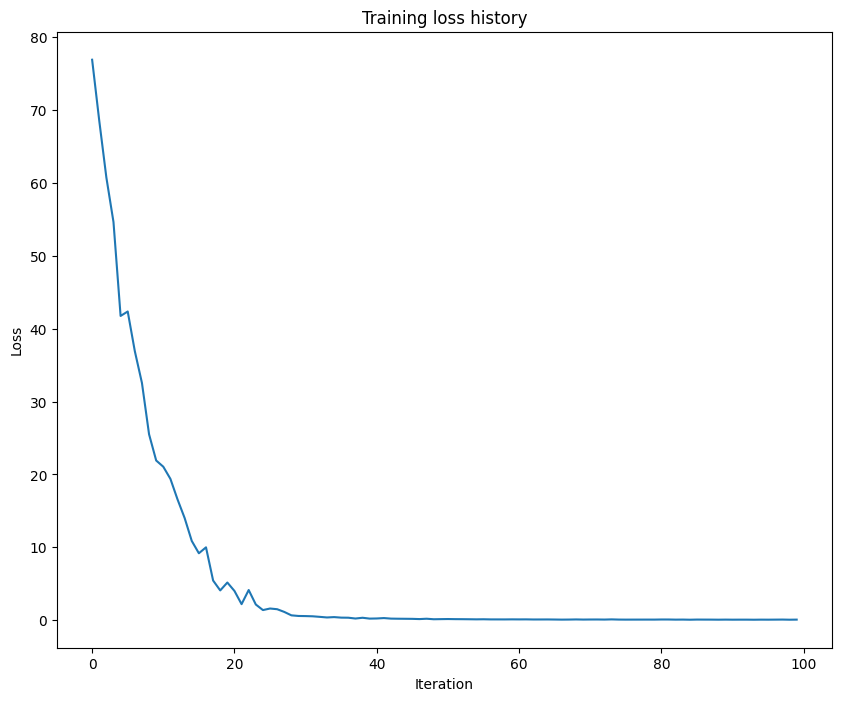

In [15]:
np.random.seed(231)

small_data = load_coco_data(max_train=50)

small_rnn_model = CaptioningRNN(
          cell_type='rnn',
          word_to_idx=data['word_to_idx'],
          input_dim=data['train_features'].shape[1],
          hidden_dim=512,
          wordvec_dim=256,
        )

small_rnn_solver = CaptioningSolver(small_rnn_model, small_data,
           update_rule='adam',
           num_epochs=50,
           batch_size=25,
           optim_config={
             'learning_rate': 5e-3,
           },
           lr_decay=0.95,
           verbose=True, print_every=10,
         )

small_rnn_solver.train()

# 计算训练损失
plt.plot(small_rnn_solver.loss_history)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training loss history')
plt.show()

# 测试时间取样
与分类模型不同，图像字幕模型在训练时和测试时的表现非常不同。在训练时，我们可以访问ground-truth标题，因此我们在每一步都向RNN输入ground-truth单词。在测试时，我们在每个时间步上从词汇表上的分布抽样，并在下一个时间步上将抽样作为输入提供给RNN。
在文件' cs231n/classifiers/rnn中。，实现用于测试时间抽样的“sample”方法。这样做之后，从您的过度拟合模型中对训练和验证数据运行以下示例。训练数据上的样本应该很好;验证数据上的示例可能没有意义。

**第 16 块｜反馈预测词并显示字幕**

从训练/验证划分各抽两个样例，用图像特征初始化隐藏状态，再从 START 开始逐词贪心解码。每步必须把当前预测传入下一步；展示原图、真实字幕和生成字幕，验证集样例用于观察小样本过拟合后的泛化局限。

前序输入：`small_data` 来自第 15 块，`data` 来自第 3 块，`small_rnn_model` 来自第 15 块。

http://farm5.staticflickr.com/4151/5003644046_1122a796c9_z.jpg


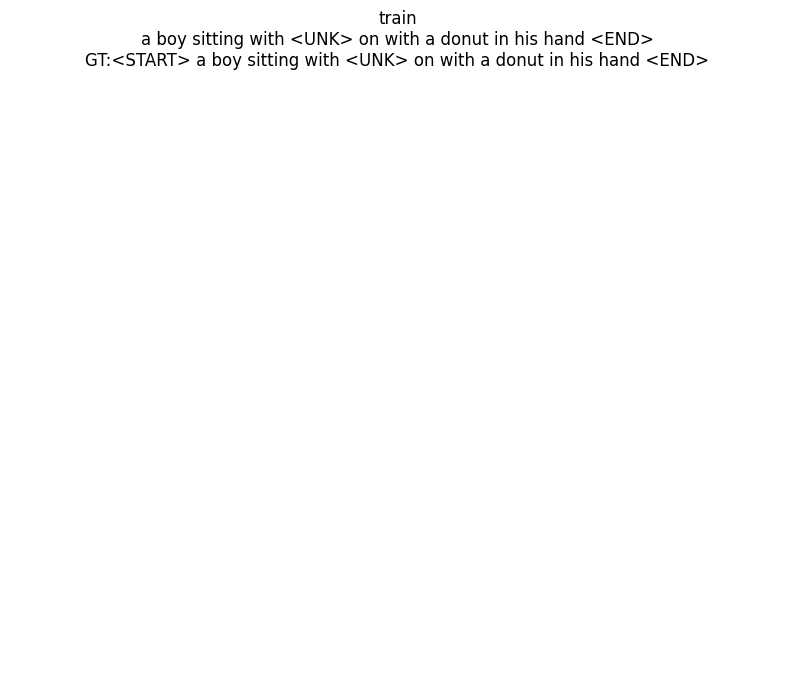

http://farm5.staticflickr.com/4134/4876982491_5359f44020_z.jpg


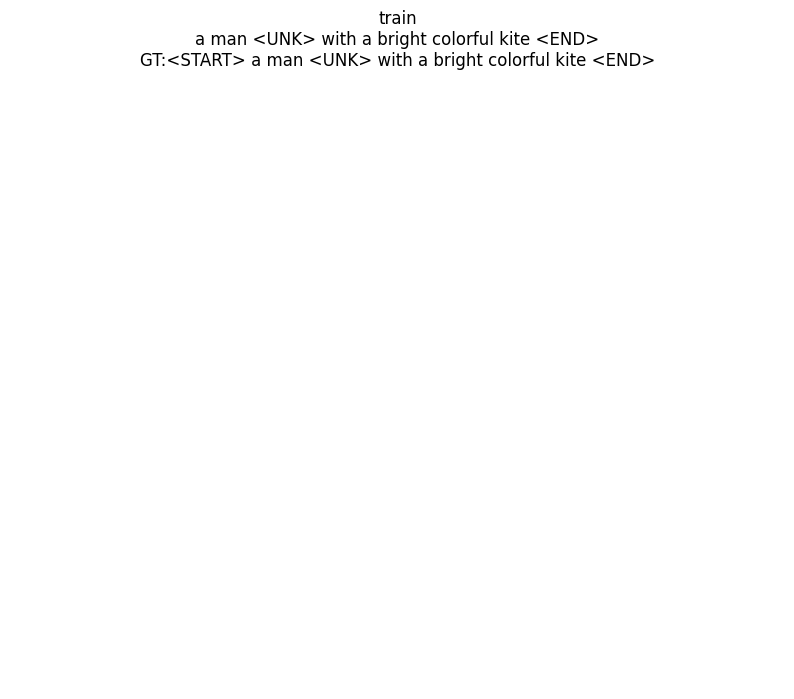

http://farm5.staticflickr.com/4086/5218606605_68fb694d6c_z.jpg


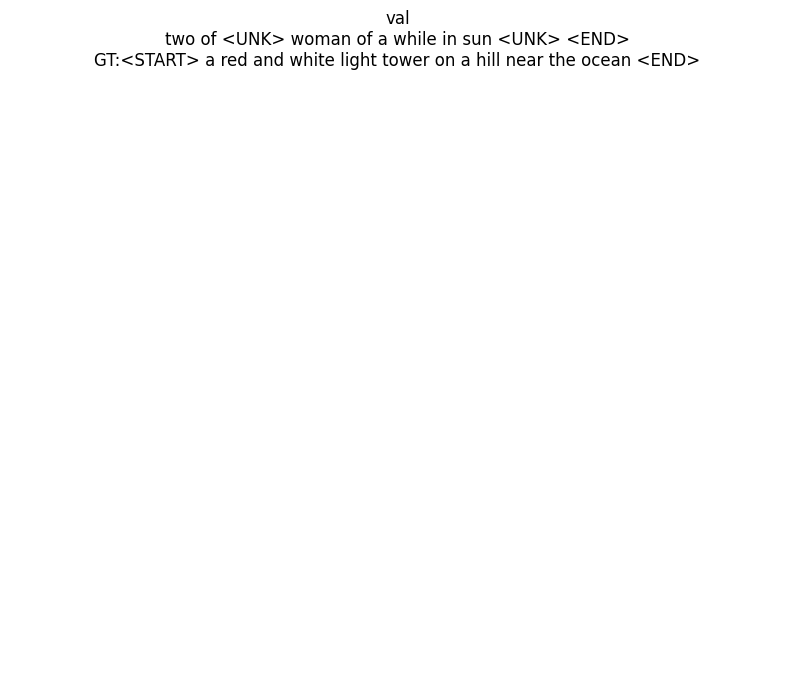

http://farm4.staticflickr.com/3019/2823442974_16c196c54c_z.jpg


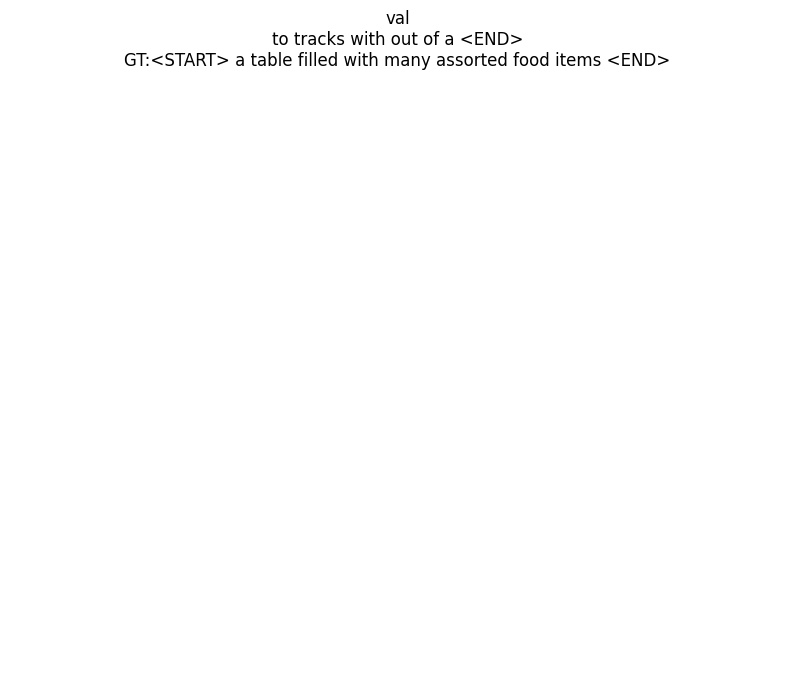

In [16]:
for split in ['train', 'val']:
    minibatch = sample_coco_minibatch(small_data, split=split, batch_size=2)
    gt_captions, features, urls = minibatch
    gt_captions = decode_captions(gt_captions, data['idx_to_word'])

    sample_captions = small_rnn_model.sample(features)
    sample_captions = decode_captions(sample_captions, data['idx_to_word'])

    for gt_caption, sample_caption, url in zip(gt_captions, sample_captions, urls):
#         plt.imshow(image_from_url(url))
        print(url)
        plt.title('%s\n%s\nGT:%s' % (split, sample_caption, gt_caption))
        plt.axis('off')
        plt.show()

## 方法二：等价 GPU 后端与完整 COCO 训练

上面的原 NumPy 前后向、梯度检查及 50 条字幕、50 轮训练保持独立。完整课程训练划分有 400,135 条字幕，使用 82,783 张图像的 512 维特征。原 CPU 路径的实测批次成本较高，因此完整数据训练采用下方经过对照验证的 GPU 实现；这是执行后端变更，不能将其结果写成 NumPy 后端的完整训练成绩。

**输入与数据流。** 图像特征通过同一仿射投影成为 h0；字幕去掉最后一个词后查表得到 256 维词向量；512 维循环层输出每个时间步的隐藏状态；共享词表投影得到 logits，与去掉 START 的目标字幕计算交叉熵。NULL 位置屏蔽，按字幕数而非有效词数归一化。

**参数对应。** PyTorch 的循环权重采用转置布局，LSTM 门序为 i/f/g/o，而原代码为 i/f/o/g，所以导入参数与对照梯度时必须换序。框架的第二组循环偏置固定为零，避免引入额外可训练自由度。课程 Adam 的时间步、偏差校正和 epsilon 位置也保持一致。验证同时覆盖 CPU/CUDA 前向、全部参数梯度、贪心解码及多步优化器更新。

**训练和输出。** 每轮无放回遍历全部训练字幕，batch size=100，保留尾批；Adam 学习率 5e-4，完整训练 20 轮，共 80,040 次更新。每轮在固定种子选出的 1,000 条验证字幕上评估损失和平均单句 BLEU-1，以验证损失选择最佳参数。检查点记录模型、优化器、数据排列、随机数和偏移位置。已有完成记录时载入并展示该实验，未完成时从检查点续训。

实现位于 [torch_captioning.py](cs231n/torch_captioning.py)，与原 [rnn.py](cs231n/classifiers/rnn.py) 分开维护。方法一不导入该模块也能独立运行。这里的 BLEU-1 是单参考句指标；同一图片的多条参考、corpus BLEU-4 等其他协议不可直接对比。

**第 17 块：顺着变量读**

本块实际导入：`cs231n.torch_captioning.verify_equivalence`、`cs231n.torch_captioning.train_gpu`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`full_course_data` → 第 19 块，`gpu_rnn_history` → 第 18 块。

In [17]:
from cs231n.torch_captioning import verify_equivalence, train_gpu
# 先证明数据流和梯度一致，再执行/恢复完整训练。
backend_equivalence = {device: verify_equivalence(device) for device in ('cpu', 'cuda')}
print(backend_equivalence)
full_course_data = load_coco_data(pca_features=True)
gpu_rnn_model, gpu_rnn_report, gpu_rnn_history = train_gpu(full_course_data, 'rnn')
print(gpu_rnn_report)


{'cpu': {'rnn': {'loss_absolute_error': 0.0, 'gradient_max_absolute_errors': {'W_embed': 1.3877787807814457e-16, 'W_proj': 1.1102230246251565e-16, 'b_proj': 3.122502256758253e-17, 'W_vocab': 1.1102230246251565e-16, 'b_vocab': 1.1102230246251565e-16, 'Wx': 3.469446951953614e-18, 'Wh': 1.6653345369377348e-16, 'b': 1.3877787807814457e-16}, 'greedy_decoding_equal': True, 'adam_three_steps_equal': True, 'device': 'cpu'}, 'lstm': {'loss_absolute_error': 0.0, 'gradient_max_absolute_errors': {'W_embed': 2.7755575615628914e-17, 'W_proj': 4.163336342344337e-17, 'b_proj': 1.3877787807814457e-17, 'W_vocab': 2.3635607360183997e-17, 'b_vocab': 2.220446049250313e-16, 'Wx': 4.336808689942018e-19, 'Wh': 2.7755575615628914e-17, 'b': 5.551115123125783e-17}, 'greedy_decoding_equal': True, 'adam_three_steps_equal': True, 'device': 'cpu'}}, 'cuda': {'rnn': {'loss_absolute_error': 8.881784197001252e-16, 'gradient_max_absolute_errors': {'W_embed': 1.6653345369377348e-16, 'W_proj': 1.6653345369377348e-16, 'b_p

### 完整训练的曲线与字幕检查

使用逐轮保存的验证损失和 BLEU-1 绘制两幅独立曲线，再打印固定验证样本的参考句与生成句。检查模型是否过拟合以及是否生成重复、泛化或错误描述；保留不理想结果，不把低验证损失直接等同于高 BLEU。

**第 18 块：顺着变量读**

本块实际导入：`study_runtime.ROOT`。各模块在本题中的职责见开头的库说明。

前序输入：`gpu_rnn_history` 来自第 17 块。

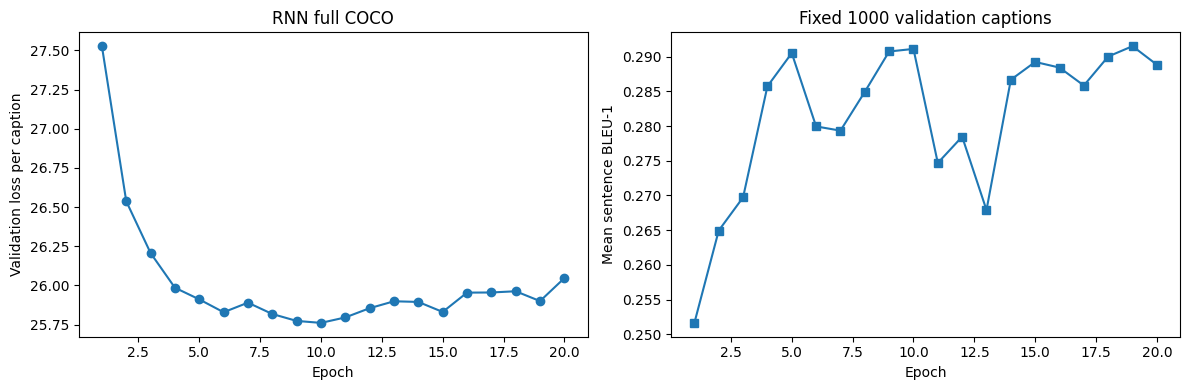

Reference: <START> the two men are <UNK> for control of the soccer ball <END>
Generated: two men are playing frisbee in a field <END>
BLEU-1: 0.2921
Reference: <START> several people walking on a platform next to a train <END>
Generated: a <UNK> train is traveling down the tracks <END>
BLEU-1: 0.1861
Reference: <START> a baby horse has its <UNK> under a big horse <END>
Generated: a horse <UNK> a <UNK> <UNK> <UNK> a <UNK> of <UNK> <END>
BLEU-1: 0.2696
Reference: <START> a large clock <UNK> the <UNK> side of a building <END>
Generated: a large clock tower with a clock on top <END>
BLEU-1: 0.4444
Reference: <START> an elephant standing on a lush green field <END>
Generated: two elephants are standing in the grass near a <UNK> <END>
BLEU-1: 0.2222
Reference: <START> a woman that has <UNK> <UNK> next to a man wearing a <UNK> <END>
Generated: a man is sitting on a toilet in a <UNK> <END>
BLEU-1: 0.3977
Reference: <START> a plate of food with a <UNK> <UNK> and colorful vegetables <END>
Genera

In [18]:
# 输入为每轮真实验证记录，输出损失和 BLEU 曲线；两个纵轴分开显示。
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [row['epoch'] for row in gpu_rnn_history]
axes[0].plot(epochs, [row['validation_loss'] for row in gpu_rnn_history], marker='o')
axes[0].set(xlabel='Epoch', ylabel='Validation loss per caption', title='RNN full COCO')
axes[1].plot(epochs, [row['validation_sentence_bleu1'] for row in gpu_rnn_history], marker='s')
axes[1].set(xlabel='Epoch', ylabel='Mean sentence BLEU-1', title='Fixed 1000 validation captions')
plt.tight_layout()
plt.show()
from study_runtime import ROOT as project_root
examples = json.loads((project_root / 'outputs' / 'full_coco_rnn_gpu_equivalent' / 'caption_examples.json').read_text(encoding='utf-8'))
for example in examples[:10]:
    print('Reference:', example['reference'])
    print('Generated:', example['prediction'])
    print('BLEU-1:', round(example['bleu1'], 4))


### 方法二的解码改进：长度归一化束搜索

贪心解码只保留每一步概率最高的一个词，无法比较多个完整句子的累积得分。这里冻结已经训练完成的模型权重，同时保留多个候选句：候选得分为累计 log 概率除以生成长度的 alpha 次方，每步保留得分最高的 k 条。长度不含 START，首次 END 计入长度；已结束候选只能继续 END，且不再增加长度或改变累计概率。没有屏蔽 UNK，也没有改变评估时的文本清洗规则。

**输入与状态。** 输入为一批图像特征和冻结模型。每个 beam 都有自己的词序列、累计得分、长度、完成标记，以及 RNN 的 h 或 LSTM 的 h/c。每步 top-k 选择后，这些对象必须按同一个父候选索引重排；只更新 token 而不重排循环状态会产生错误的条件概率。输出是每张图得分最高的 token 序列，再按原规则转成文字。

**如何选择和确认。** 先检查宽度 1、alpha=0 的文本与原贪心完全一致，再在原固定 1000 条验证字幕上比较贪心以及宽度 3/5、alpha 0/0.6/1.0 的组合。依据该开发子集的 BLEU-1 选方案，然后从其余验证图像中抽取另一组 1000 条字幕复核，两组图像集合不重叠。确认集不用于挑选束宽或长度系数，避免把同一子集的调参收益当作泛化保证。

该方法不增加训练更新，模型、数据和 BLEU 定义保持不变，新增成本是推理搜索。结果包含开发与确认指标、逐句改善比例和耗时；如果候选没有超过贪心，就保留原选择，不强行声称改进。实现见 [beam_search.py](cs231n/beam_search.py)。

**第 19 块：顺着变量读**

本块实际导入：`cs231n.beam_search.compare_decoding`。各模块在本题中的职责见开头的库说明。

前序输入：`full_course_data` 来自第 17 块。

In [19]:
from cs231n.beam_search import compare_decoding
beam_rnn_report = compare_decoding(full_course_data, 'rnn')
assert beam_rnn_report['width1_matches_greedy']
assert beam_rnn_report['image_sets_disjoint']
print(json.dumps(beam_rnn_report, ensure_ascii=False, indent=2))


{"width": 0, "length_alpha": 0, "development_bleu1": 0.2911053153125523, "seconds": 0.10730810000677593}


{"width": 3, "length_alpha": 0, "development_bleu1": 0.30048095521479024, "seconds": 0.17914329998893663}

{"width": 3, "length_alpha": 0.6, "development_bleu1": 0.3015233565395975, "seconds": 0.14726209999935236}


{"width": 3, "length_alpha": 1.0, "development_bleu1": 0.3023179372079496, "seconds": 0.13471480000589509}


{"width": 5, "length_alpha": 0, "development_bleu1": 0.2994901623212652, "seconds": 0.16175600000133272}


{"width": 5, "length_alpha": 0.6, "development_bleu1": 0.29866163260647327, "seconds": 0.18024489999515936}

{"width": 5, "length_alpha": 1.0, "development_bleu1": 0.29763871764834837, "seconds": 0.1733315000019502}


{"cell_type": "rnn", "model_checkpoint_epoch": 10, "selection": "maximum development mean sentence BLEU-1; confirmation not used for selection", "development_captions": 1000, "confirmation_captions": 1000, "image_sets_disjoint": true, "width1_matches_greedy": true, "candidates": [{"width": 0, "length_alpha": 0, "development_bleu1": 0.2911053153125523, "seconds": 0.10730810000677593}, {"width": 3, "length_alpha": 0, "development_bleu1": 0.30048095521479024, "seconds": 0.17914329998893663}, {"width": 3, "length_alpha": 0.6, "development_bleu1": 0.3015233565395975, "seconds": 0.14726209999935236}, {"width": 3, "length_alpha": 1.0, "development_bleu1": 0.3023179372079496, "seconds": 0.13471480000589509}, {"width": 5, "length_alpha": 0, "development_bleu1": 0.2994901623212652, "seconds": 0.16175600000133272}, {"width": 5, "length_alpha": 0.6, "development_bleu1": 0.29866163260647327, "seconds": 0.18024489999515936}, {"width": 5, "length_alpha": 1.0, "development_bleu1": 0.29763871764834837,

{
  "cell_type": "rnn",
  "model_checkpoint_epoch": 10,
  "selection": "maximum development mean sentence BLEU-1; confirmation not used for selection",
  "development_captions": 1000,
  "confirmation_captions": 1000,
  "image_sets_disjoint": true,
  "width1_matches_greedy": true,
  "candidates": [
    {
      "width": 0,
      "length_alpha": 0,
      "development_bleu1": 0.2911053153125523,
      "seconds": 0.10730810000677593
    },
    {
      "width": 3,
      "length_alpha": 0,
      "development_bleu1": 0.30048095521479024,
      "seconds": 0.17914329998893663
    },
    {
      "width": 3,
      "length_alpha": 0.6,
      "development_bleu1": 0.3015233565395975,
      "seconds": 0.14726209999935236
    },
    {
      "width": 3,
      "length_alpha": 1.0,
      "development_bleu1": 0.3023179372079496,
      "seconds": 0.13471480000589509
    },
    {
      "width": 5,
      "length_alpha": 0,
      "development_bleu1": 0.2994901623212652,
      "seconds": 0.16175600000133272
   

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**第 20 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [20]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '011_RNN_Captioning')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际修复。** 自回归采样必须把预测词反馈到下一步，原代码遗漏了该更新，现已通过针对性 token 流测试。

**训练层次。** 原 NumPy 小样本实验与完整数据 GPU 实验各自保留。GPU 的公式、参数、梯度、解码和优化器都作了对照，浮点后端差异不被写成逐位相同。

**质量边界。** 单参考 BLEU-1 只衡量词重合和长度惩罚，可能奖励泛化句式。需同时检查语义、重复词、UNK 与图片内容，不能只优化一个分数。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。